# Modelo 8 — Isolation Forest

In [7]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    fbeta_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.preprocessing import RobustScaler

raiz = Path.cwd()
if not (raiz / 'models' / 'modelo-5' / 'painel.parquet').exists():
    for pasta in Path.cwd().parents:
        candidato = pasta / 'models' / 'modelo-5' / 'painel.parquet'
        if candidato.exists():
            raiz = pasta
            break

painel = pd.read_parquet(raiz / 'models' / 'modelo-5' / 'painel.parquet')
painel['Data'] = pd.to_datetime(painel['Data'])

In [8]:
PROIBIDAS = {'n_falhas_7d_futuro', 'n_mdu_7d'}
PRIORIDADE = ('n_LSD', 'n_long30', 'n_tecnicos', 'dur_max', 'n_FO', 'n_FC', 'n_RCE')
feats = [
    c for c in painel.columns
    if c not in PROIBIDAS
    and (c.startswith('n_') or c.startswith('dur_') or c.startswith('zm01_'))
    and pd.api.types.is_numeric_dtype(painel[c])
]
print(len(feats), 'features')

64 features


In [9]:
FIM_FIT = pd.Timestamp('2025-01-23')
INI_VALID = pd.Timestamp('2025-01-31')
FIM_VALID = pd.Timestamp('2025-04-23')
INI_TESTE = pd.Timestamp('2025-05-01')

fit = painel[(painel['Data'] <= FIM_FIT) & (painel['y'] == 0)].copy()
valid = painel[painel['Data'].between(INI_VALID, FIM_VALID)].copy()
teste = painel[painel['Data'] >= INI_TESTE].copy()
base_porta = fit.groupby('id_porta')[feats].median()


def montar_X(df):
    bruto = df[feats].replace([np.inf, -np.inf], np.nan).fillna(0)
    ref = base_porta.reindex(df['id_porta'].values)
    ref.index = bruto.index
    X = bruto.sub(ref.fillna(0))
    for c in X.columns:
        if c.startswith(PRIORIDADE):
            X[c] = X[c] * 2.5
    return X


X_fit = montar_X(fit)
X_va, y_va = montar_X(valid), valid['y'].astype(int).to_numpy()
X_te, y_te = montar_X(teste), teste['y'].astype(int).to_numpy()
print(len(X_fit), len(X_va), len(X_te))

179467 35520 71184


In [10]:
scaler = RobustScaler()
X_fit_s = scaler.fit_transform(X_fit)
X_va_s = scaler.transform(X_va)
X_te_s = scaler.transform(X_te)

iso = IsolationForest(
    n_estimators=400,
    max_samples=min(8192, len(X_fit)),
    contamination='auto',
    random_state=42,
    n_jobs=-1,
)
iso.fit(X_fit_s)


def rank01(v):
    s = pd.Series(v)
    return s.rank(method='average', pct=True).to_numpy()


proxy_va = valid[['n_LSD_7d', 'n_long30_7d', 'n_tecnicos_7d', 'dur_max_7d']].sum(axis=1).to_numpy()
proxy_te = teste[['n_LSD_7d', 'n_long30_7d', 'n_tecnicos_7d', 'dur_max_7d']].sum(axis=1).to_numpy()
iso_va = -iso.score_samples(X_va_s)
iso_te = -iso.score_samples(X_te_s)

melhor = (-1.0, 0.5, 0.0)
for w in np.linspace(0.15, 0.85, 15):
    score = w * rank01(iso_va) + (1 - w) * rank01(proxy_va)
    for t in np.unique(np.quantile(score, np.linspace(0.55, 0.92, 50))):
        f2 = fbeta_score(y_va, score >= t, beta=2, zero_division=0)
        if f2 > melhor[0]:
            melhor = (f2, w, float(t))

f2_va, peso, limiar = melhor
score_va = peso * rank01(iso_va) + (1 - peso) * rank01(proxy_va)
score_te = peso * rank01(iso_te) + (1 - peso) * rank01(proxy_te)
pred_te = (score_te >= limiar).astype(int)

print('peso IF / proxy:', round(peso, 2), round(1 - peso, 2), '| limiar:', round(limiar, 4), '| F2 val:', round(f2_va, 3))
print('PR-AUC teste:', round(average_precision_score(y_te, score_te), 4), '| baseline:', round(float(y_te.mean()), 4))
print('classe 1  P:', round(precision_score(y_te, pred_te, zero_division=0), 3),
      'R:', round(recall_score(y_te, pred_te, zero_division=0), 3),
      'F2:', round(fbeta_score(y_te, pred_te, beta=2, zero_division=0), 3))
print(classification_report(y_te, pred_te, digits=3, zero_division=0))

peso IF / proxy: 0.25 0.75 | limiar: 0.4676 | F2 val: 0.324
PR-AUC teste: 0.0977 | baseline: 0.0871
classe 1  P: 0.113 R: 0.585 F2: 0.318
              precision    recall  f1-score   support

           0      0.934     0.560     0.701     64982
           1      0.113     0.585     0.189      6202

    accuracy                          0.563     71184
   macro avg      0.523     0.573     0.445     71184
weighted avg      0.862     0.563     0.656     71184



In [11]:
def n_inicios(df, col):
    s = df.sort_values(['id_porta', 'Data'])
    flag = s[col].astype(bool)
    prev = flag.groupby(s['id_porta']).shift(1).fillna(False).astype(bool)
    return int((flag & ~prev).sum())


def eventos_pegos(df, y_col, pred_col):
    s = df.sort_values(['id_porta', 'Data']).copy()
    y = s[y_col].astype(bool)
    novo = y & ~y.groupby(s['id_porta']).shift(1).fillna(False).astype(bool)
    s['_eid'] = novo.groupby(s['id_porta']).cumsum()
    falhas = s[y]
    if falhas.empty:
        return 0, 0
    grupos = falhas.groupby(['id_porta', '_eid'], sort=False)
    return int(grupos[pred_col].max().sum()), int(grupos.ngroups)


avaliar = teste.copy()
avaliar['pred'] = pred_te
avaliar['y'] = y_te
pegos, n_eventos = eventos_pegos(avaliar, 'y', 'pred')
n_avisos = n_inicios(avaliar, 'pred')
avisos_ok, _ = eventos_pegos(avaliar, 'pred', 'y')
print('eventos', n_eventos, 'pegos', pegos, 'recall evento', round(pegos / n_eventos, 3) if n_eventos else 0)
print('avisos', n_avisos, 'acertaram', avisos_ok, 'precisão evento', round(avisos_ok / n_avisos, 3) if n_avisos else 0)

eventos 813 pegos 577 recall evento 0.71
avisos 2297 acertaram 516 precisão evento 0.225


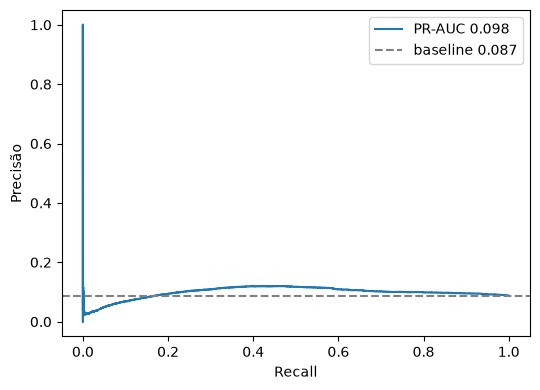

In [12]:
fig, ax = plt.subplots(figsize=(5.5, 4))
p, r, _ = precision_recall_curve(y_te, score_te)
ax.plot(r, p, label=f'PR-AUC {average_precision_score(y_te, score_te):.3f}')
ax.axhline(y_te.mean(), color='gray', linestyle='--', label=f'baseline {y_te.mean():.3f}')
ax.set_xlabel('Recall')
ax.set_ylabel('Precisão')
ax.legend()
fig.tight_layout()
plt.show()